In [1]:
## using my_env 
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
from scipy.ndimage import gaussian_filter
import pandas as pd
import elr_c as elr
import utils_b as utils

In [2]:
weekn =1

In [3]:
elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{weekn}_2022_2024.nc')['prcp']
qrf_prob =np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{weekn}_tuned_terciles_2022_2024.npy')
classes = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_Week{weekn}_2022_2024.nc")['prcp']


In [4]:
#This function didn't work 
def smooth_qrf_probs(qrf_prob, sigma=1):
    """
    Apply Gaussian smoothing to each probability class in spatial dimensions.

    Parameters:
    - qrf_prob: np.ndarray of shape (32, 31, 50, 3)
    - sigma: standard deviation for Gaussian kernel

    Returns:
    - Smoothed array of same shape as input
    """
    smoothed = np.empty_like(qrf_prob)
    
    for t in range(qrf_prob.shape[2]):  # over 50 time steps
        for cls in range(qrf_prob.shape[3]):  # over 3 probability classes
            smoothed[:, :, t, cls] = gaussian_filter(qrf_prob[:, :, t, cls], sigma=sigma)

    return smoothed


In [5]:
import numpy as np

def rps_forecast(class_value, probs, grid_point=None, return_mean=False):
    """
    Calculate the Ranked Probability Score (RPS) while ignoring rows with any NaN values.
    
    Parameters:
    - class_value (np.ndarray): Array of class values.
    - probs (np.ndarray): Array of forecast probabilities.
    - grid_point (tuple): Optional, specific grid point (i, j) for calculating RPS.
    - return_mean (bool): If True, return the mean RPS across forecasts.

    Returns:
    - np.ndarray or float: RPS for each forecast, or mean RPS if return_mean is True.
    """
    
    # If a specific grid point is provided, extract relevant data
    if grid_point is not None:
        class_value = class_value[grid_point[0], grid_point[1], :]
        probs = probs[grid_point[0], grid_point[1], :]

    # Identify valid rows where neither class_value nor probs contain NaNs
    valid_mask = ~np.isnan(class_value).any(axis=1) & ~np.isnan(probs).any(axis=1)
    
    # Initialize an array to store the RPS values, filled with NaNs
    rps_values = np.full(class_value.shape[0], np.nan)
    
    # Calculate RPS only for valid rows
    if valid_mask.any():  # Check if there are any valid rows
        filtered_class_value = class_value[valid_mask]
        filtered_probs = probs[valid_mask]
        
        # Calculate cumulative sums
        cum_obs = np.cumsum(filtered_class_value, axis=1)
        cum_fc_probs = np.cumsum(filtered_probs, axis=1).round(3)
        
        # Calculate the RPS values for the valid rows
        values = np.sum((cum_fc_probs - cum_obs) ** 2, axis=1)
        
        # Store the RPS values in the corresponding positions of the result array
        rps_values[valid_mask] = values
    
    # Return the mean of the valid RPS values if return_mean is True
    if return_mean:
        return np.nanmean(rps_values)
    else:
        return rps_values, np.sum(valid_mask)

In [6]:
def rps_forecast_simple(class_value, probs, grid_point=None, return_mean = False):
    """
    grid_point: optional if only a single point is being fed as an input
    """
    
    if grid_point is not None:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_fc_probs = np.cumsum(probs[grid_point[0], grid_point[1]], axis=1)
        values = ((cum_fc_probs-cum_obs)**2)
    else:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_fc_probs = np.cumsum(probs, axis=1).round(3)
        values = ((cum_fc_probs-cum_obs)**2)
        
    
    if len(class_value.shape)>1:
        if return_mean:
            return np.mean(np.sum(values, axis=1))
        else:
            return np.sum(values, axis=1)
    else:
        return np.sum(values)

In [7]:
def rps_clim(class_value):
    
    if len(class_value.shape)>1:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_clim_probs = np.cumsum(np.ones((class_value.shape[0],3))*0.3333, axis=1).round(3)
        values = ((cum_clim_probs-cum_obs)**2)/(class_value.shape[1]-1)
    else:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_clim_probs = np.cumsum(np.ones(3)*0.3333, axis=0).round(3)
        values = ((cum_clim_probs-cum_obs)**2)/(class_value.shape[0]-1)
    
    
    if len(class_value.shape)>1:
        return np.mean(np.sum(values, axis=1))
    else:
        return np.sum(values)

In [8]:
import numpy as np
import xarray as xr
from scipy.stats import binomtest

def compute_significant_diff_grid(smqrf_rps: xr.DataArray, smelr_rps: xr.DataArray, alpha: float = 0.10):
    """
    Performs a binomial test between two RPS datasets at each grid point.

    Parameters:
    ----------
    smqrf_rps : xr.DataArray
        RPS values from QRF model with shape (Y, X, time)
    smelr_rps : xr.DataArray
        RPS values from ELR model with shape (Y, X, time)
    alpha : float
        Significance level for the binomial test (default: 0.05)

    Returns:
    -------
    significant_indices : list of [i, j]
        List of grid points where QRF and ELR RPS are significantly different.
    """
    significant_indices = []
    significant_lat_lon = []
    T,Y, X = smqrf_rps.shape

    for i in range(Y):
        for j in range(X):
            RPS_A = smqrf_rps[:, i, j].values
            RPS_B = smelr_rps[:, i, j].values

            if np.all(np.isnan(RPS_A)) or np.all(np.isnan(RPS_B)):
                continue

            d = RPS_A - RPS_B
            d = d[~np.isnan(d)]

            if d.size == 0:
                continue

            signs = np.sign(d)
            n_plus = np.sum(signs > 0)
            n_minus = np.sum(signs < 0)
            n_nonzero = n_plus + n_minus

            if n_nonzero == 0:
                continue

            pval = binomtest(n_plus, n=n_nonzero, p=0.5, alternative='two-sided').pvalue

            if pval < alpha:
                significant_indices.append([i, j])
                significant_lat_lon.append([smqrf_rps["Y"][i].values.item(),smqrf_rps["X"][j].values.item() ])
                #print(f"Grid ({i}, {j}): p = {pval:.4f} → Significant")
           # else:
                #print(f"Grid ({i}, {j}): p = {pval:.4f} → Not Significant")

    return significant_indices, significant_lat_lon


In [9]:
from scipy.ndimage import gaussian_filter

def smooth_xarray_with_nan(data, sigma=1, iterations=1):
    """
    Applies iterative spatial Gaussian smoothing along the first dimension (dim=0) 
    of an xarray DataArray while handling NaNs properly.
    
    Parameters:
    - data: xarray.DataArray of shape (50, 32, 31)
    - sigma: Smoothing standard deviation for Gaussian filter
    - iterations: Number of times to apply the smoothing iteratively
    
    Returns:
    - Smoothed xarray.DataArray
    """
    smoothed_data = data.copy()

    for _ in range(iterations):
        smoothed_list = []
        for i in range(data.shape[0]):  # Iterate over dim=0 (50 slices)
            slice_data = smoothed_data.isel({data.dims[0]: i})  # Extract 2D slice
            nan_mask = np.isnan(slice_data)  # Identify NaNs
            filled_data = slice_data.fillna(slice_data.mean())  # Fill NaNs with mean
            smoothed_slice = gaussian_filter(filled_data, sigma=sigma)  # Apply smoothing
            smoothed_slice = xr.DataArray(smoothed_slice, coords=slice_data.coords, dims=slice_data.dims)
            smoothed_slice = smoothed_slice.where(~nan_mask)  # Restore NaNs
            smoothed_list.append(smoothed_slice)

        # Reconstruct full DataArray
        smoothed_data = xr.concat(smoothed_list, dim=data.dims[0])

    return smoothed_data


In [10]:
# Load the shapefile
shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/indian_borders.shp"  # Update with your actual file path
State_shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/sd_boundary.shp"  # Update with your actual file path
gdf = gpd.read_file(shapefile_path)
gdf_st = gpd.read_file(State_shapefile_path)

/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_33968/1069412761.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.12, 1, 1])  # Leave space for colorbars


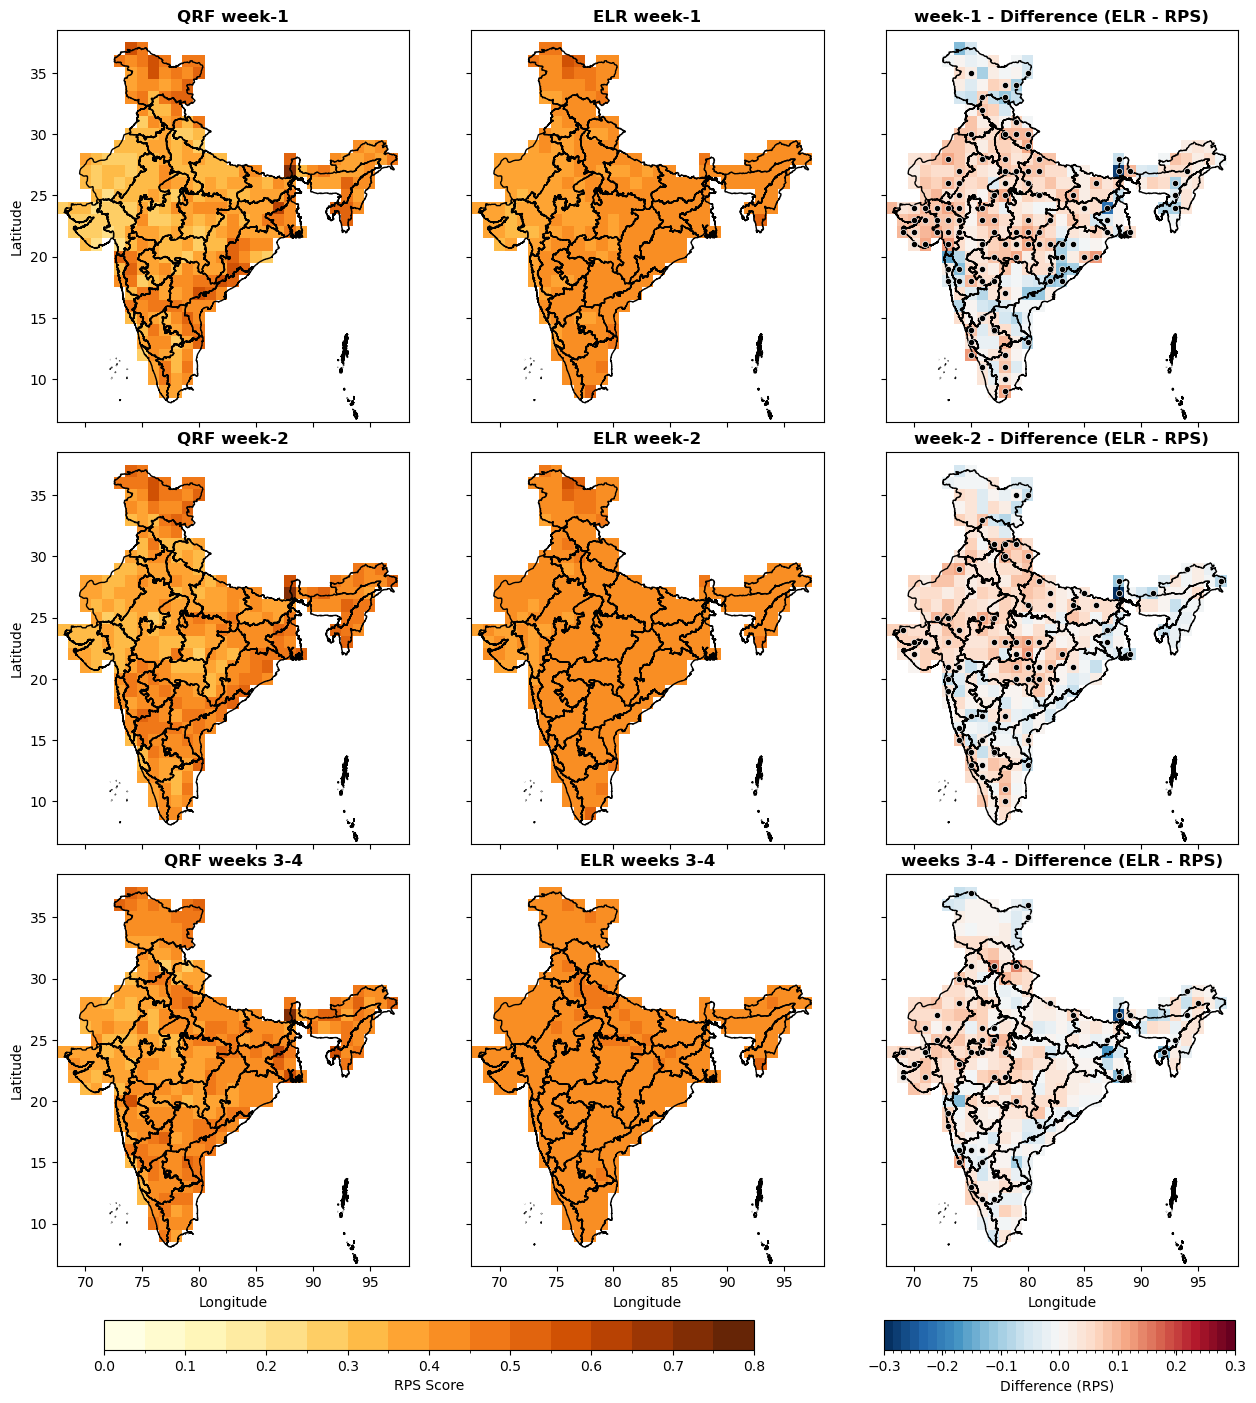

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

weekn = [1, 2, 34]
titles = ['week-1', 'week-2', 'weeks 3-4']
title_fontsize = 12
# Create a 3x3 subplot layout
fig, axes = plt.subplots(3, 3, figsize=(13, 15), sharex=True, sharey=True)

# Colorbar and level settings
orange_cmap = 'YlOrBr'  # Color scheme for first two plots
rps_vmin, rps_vmax = 0, 0.8  # Limits for first two plots
rps_levels = 17  # Number of levels for first two plots
diff_vmin, diff_vmax = -0.3, 0.3  # Limits for third plot
diff_levels = 41  # Number of levels for third plot

# Store colorbar objects for first two columns and third column
contours_orange = []
contours_rdbu = []

for i, (week, title) in enumerate(zip(weekn, titles)):
    # Load data for the current week
    elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{week}_2022_2024.nc')['prcp']
    qrf_prob = np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{week}_tuned_terciles_2022_2024.npy')
    classes = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_Week{week}_2022_2024.nc")['prcp']

    class_values = classes.values
    probs = elr_probs.values

    rps_elr = rps_forecast_simple(class_values, probs)
    qrf_prob_rotated = np.transpose(qrf_prob, axes=(2, 3, 0, 1))
    rps_qrf = rps_forecast_simple(class_values, qrf_prob_rotated)

    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]
    
    qrf_rps = xr.DataArray(rps_qrf, dims=["T", "Y", "X"], coords={"T": T, "Y": Y, "X": X}, name="rps")
    elr_rps = xr.DataArray(rps_elr, dims=["T", "Y", "X"], coords={"T": T, "Y": Y, "X": X}, name="rps")

    smqrf_rps = smooth_xarray_with_nan(qrf_rps, sigma=1, iterations=1)
    smelr_rps = smooth_xarray_with_nan(elr_rps, sigma=1, iterations=1)
    
    significant_points, significant_lat_lon = compute_significant_diff_grid(qrf_rps, elr_rps)

    rps_ELR = np.mean(rps_elr, axis=0)
    rps_ELR_week = xr.DataArray(rps_ELR, dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rps")
    smrps_ELR_week = smooth_xarray_with_nan(rps_ELR_week, sigma=1, iterations=1)

    rps_QRF = np.mean(rps_qrf, axis=0)
    rps_QRF_week = xr.DataArray(rps_QRF, dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rps")
    smrps_QRF_week = smooth_xarray_with_nan(rps_QRF_week, sigma=1, iterations=1)

    # Plot 3 panels for each week
    row = i  # Each week gets its own row

    # Plot first panel (QRF RPS)
    contour1 = rps_QRF_week.plot(ax=axes[row, 0], cmap=orange_cmap, levels=rps_levels, vmin=rps_vmin, vmax=rps_vmax, add_colorbar=False)
    axes[row, 0].set_title(f'QRF {title}', fontsize=title_fontsize,weight='bold')
    contours_orange.append(contour1)
    # Overlay shapefile
    gdf_st.plot(ax=axes[row, 0], color="none", edgecolor="black", linewidth=1)

    # Plot second panel (ELR RPS)
    contour2 = rps_ELR_week.plot(ax=axes[row, 1], cmap=orange_cmap, levels=rps_levels, vmin=rps_vmin, vmax=rps_vmax, add_colorbar=False)
    axes[row, 1].set_title(f'ELR {title}', fontsize=title_fontsize,weight='bold')
    contours_orange.append(contour2)
    # Overlay shapefile
    gdf_st.plot(ax=axes[row, 1], color="none", edgecolor="black", linewidth=1)

    # Plot third panel (Difference)
    diff = rps_ELR_week - rps_QRF_week
    contour3 = diff.plot(ax=axes[row, 2], cmap='RdBu_r', levels=diff_levels, vmin=diff_vmin, vmax=diff_vmax, add_colorbar=False)
    axes[row, 2].set_title(f'{title} - Difference (ELR - RPS)', fontsize=title_fontsize,weight='bold')
    contours_rdbu.append(contour3)
    # Overlay shapefile
    gdf_st.plot(ax=axes[row, 2], color="none", edgecolor="black", linewidth=1)

    # Overlay significant points only on the last subplot of each row
    for j in range(len(significant_points)):  
        y_value = significant_lat_lon[j][0]  # Extract latitude
        x_value = significant_lat_lon[j][1]  # Extract longitude
        axes[row, 2].scatter(x_value, y_value, color='black', marker='o', s=20, edgecolor='white', linewidth=0.5)

# **Set axis labels only where necessary**
for row in range(3):
    for col in range(3):
        if col == 0:  # Latitude labels only for leftmost column
            axes[row, col].set_ylabel("Latitude")
        else:
            axes[row, col].set_ylabel("")  # Remove unnecessary labels

for col in range(3):
    for row in range(3):
        if row == 2:  # Longitude labels only for bottom row
            axes[row, col].set_xlabel("Longitude")
        else:
            axes[row, col].set_xlabel("")  # Remove unnecessary labels

# **Create a single horizontal colorbar for first two columns (Oranges)**
cbar_ax1 = fig.add_axes([0.1, 0.1, 0.5, 0.02])  # [left, bottom, width, height]
cbar1 = fig.colorbar(contours_orange[0], cax=cbar_ax1, orientation='horizontal')
cbar1.set_label("RPS Score")
cbar1.set_ticks([0,0.1, 0.2,0.3, 0.4, 0.5, 0.6, 0.7, 0.8])

# **Create a separate horizontal colorbar for the third column (RdBu_r)**
cbar_ax2 = fig.add_axes([0.7, 0.1, 0.27, 0.02])  # [left, bottom, width, height]
cbar2 = fig.colorbar(contours_rdbu[0], cax=cbar_ax2, orientation='horizontal')
cbar2.set_label("Difference (RPS) ")
cbar2.set_ticks([-0.3,-0.2, -0.1, 0, 0.1, 0.2,0.3])

# Adjust layout
plt.tight_layout(rect=[0, 0.12, 1, 1])  # Leave space for colorbars
plt.savefig("/Users/bohar/Documents/abstract_papers/QRF/figures/rps_plot_without_smoothing.pdf", format="pdf", dpi=300)
plt.show()


In [12]:
# Domain-mean RPS over all test dates and grid points
domain_mean_qrf = qrf_rps.mean(dim=["T", "Y", "X"], skipna=True).item()
domain_mean_elr = elr_rps.mean(dim=["T", "Y", "X"], skipna=True).item()

# Domain-mean RPS difference: positive means QRF has lower RPS than ELR
domain_mean_diff = (
    (elr_rps - qrf_rps)
    .mean(dim=["T", "Y", "X"], skipna=True)
    .item()
)

/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_5173/952560701.py:135: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.12, 1, 1])


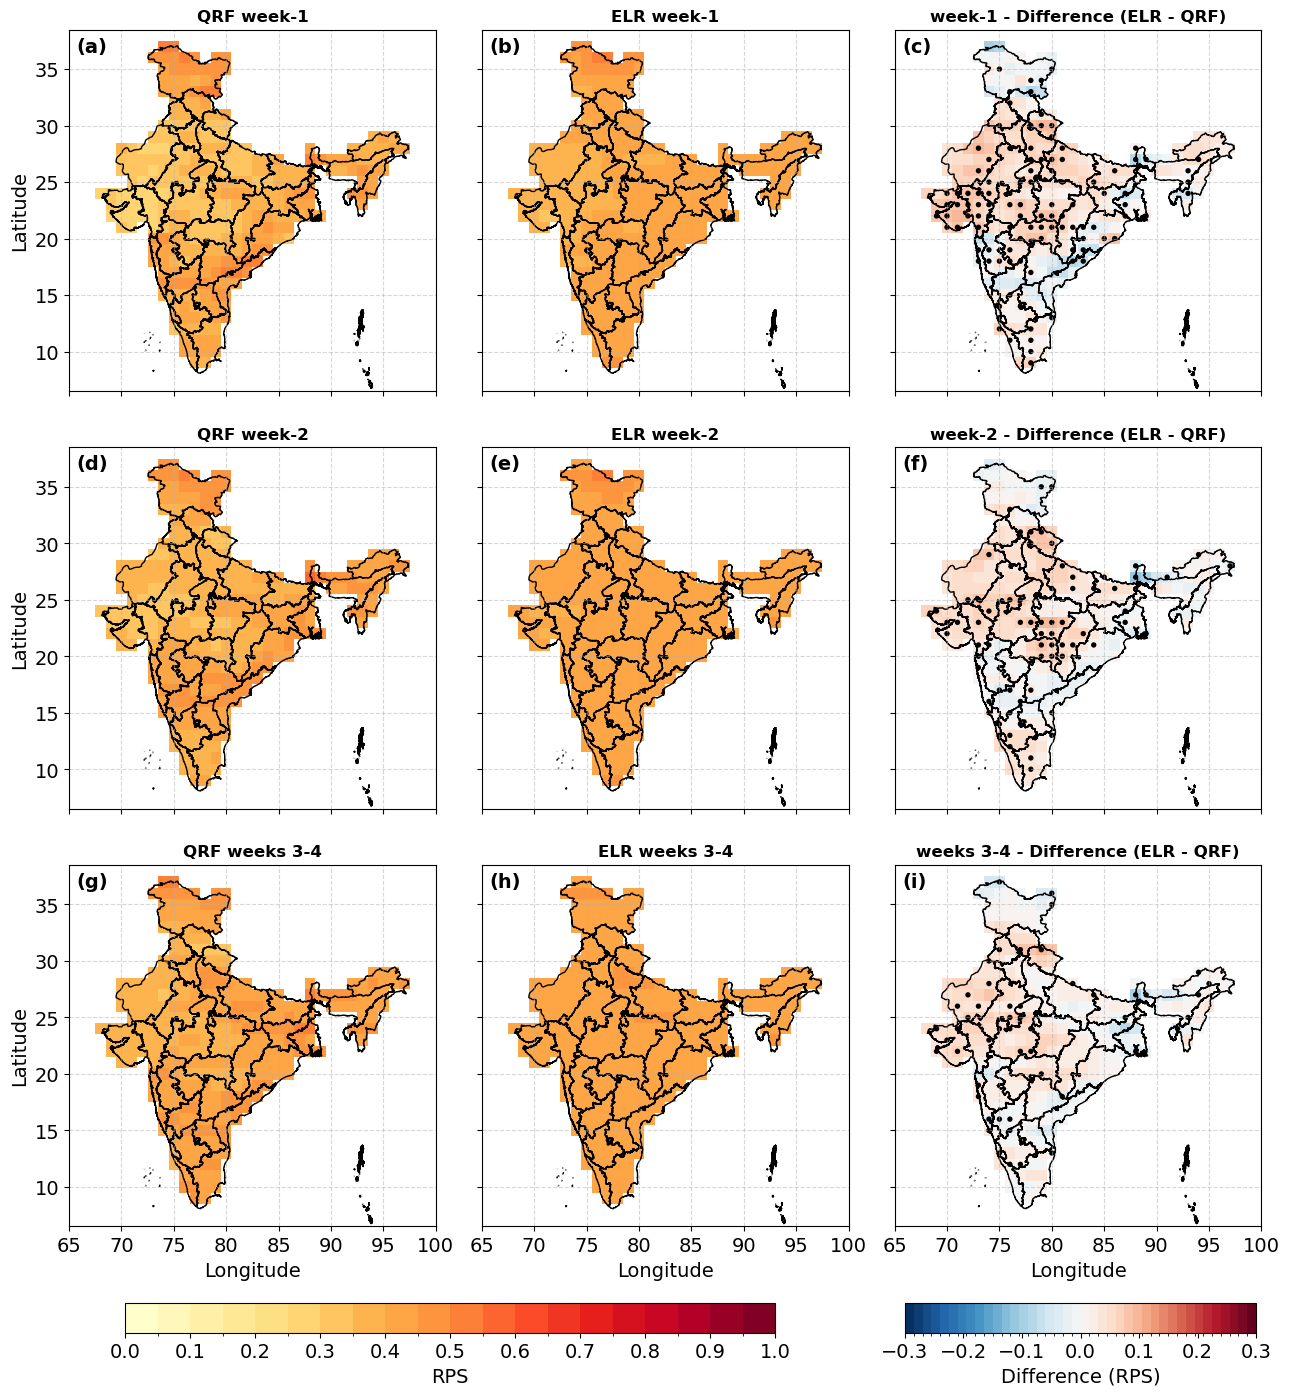

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

weekn = [1, 2, 34]

# Create a 3x3 subplot layout
fig, axes = plt.subplots(3, 3, figsize=(13, 15), sharex=True, sharey=True)

# Colorbar and level settings
#orange_cmap = 'YlOrBr' 
orange_cmap = 'YlOrRd' 
rps_vmin, rps_vmax = 0, 1.0  
rps_levels = 21  
diff_vmin, diff_vmax = -0.3, 0.3  
diff_levels = 41  

# Font size settings for publication-quality plot
label_fontsize = 14
tick_fontsize = 14
title_fontsize = 12
colorbar_fontsize = 14
titles = [
    'week-1', 'week-2', 'weeks 3-4',
    
]

# Store colorbar objects
contours_orange = []
contours_rdbu = []

#for i, week in enumerate(weekn):
for i, (week, title) in enumerate(zip(weekn, titles)):
    # Load data for the current week
    elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{week}_2022_2024.nc')['prcp']
    qrf_prob = np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{week}_tuned_terciles_2022_2024.npy')
    classes = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_Week{week}_2022_2024.nc")['prcp']

    class_values = classes.values
    probs = elr_probs.values

    rps_elr = rps_forecast_simple(class_values, probs)
    qrf_prob_rotated = np.transpose(qrf_prob, axes=(2, 3, 0, 1))
    rps_qrf = rps_forecast_simple(class_values, qrf_prob_rotated)

    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]
    
    qrf_rps = xr.DataArray(rps_qrf, dims=["T", "Y", "X"], coords={"T": T, "Y": Y, "X": X}, name="rps")
    elr_rps = xr.DataArray(rps_elr, dims=["T", "Y", "X"], coords={"T": T, "Y": Y, "X": X}, name="rps")

    smqrf_rps = smooth_xarray_with_nan(qrf_rps, sigma=1, iterations=1)
    smelr_rps = smooth_xarray_with_nan(elr_rps, sigma=1, iterations=1)
    
    significant_points, significant_lat_lon = compute_significant_diff_grid(qrf_rps, elr_rps)

    rps_ELR = np.mean(rps_elr, axis=0)
    smrps_ELR_week = smooth_xarray_with_nan(xr.DataArray(rps_ELR, dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rps"), sigma=1, iterations=1)

    rps_QRF = np.mean(rps_qrf, axis=0)
    smrps_QRF_week = smooth_xarray_with_nan(xr.DataArray(rps_QRF, dims=["Y", "X"], coords={"Y": Y, "X": X}, name="rps"), sigma=1, iterations=1)

    row = i  

    # First panel (QRF RPS)
    contour1 = smrps_QRF_week.plot(ax=axes[row, 0], cmap=orange_cmap, levels=rps_levels, vmin=rps_vmin, vmax=rps_vmax, add_colorbar=False)
    axes[row, 0].set_title(f'QRF {title}', fontsize=title_fontsize,weight='bold')
    contours_orange.append(contour1)
    gdf_st.plot(ax=axes[row, 0], color="none", edgecolor="black", linewidth=1)

    # Second panel (ELR RPS)
    contour2 = smrps_ELR_week.plot(ax=axes[row, 1], cmap=orange_cmap, levels=rps_levels, vmin=rps_vmin, vmax=rps_vmax, add_colorbar=False)
    axes[row, 1].set_title(f'ELR {title}', fontsize=title_fontsize,weight='bold')
    contours_orange.append(contour2)
    gdf_st.plot(ax=axes[row, 1], color="none", edgecolor="black", linewidth=1)

    # Third panel (Difference)
    diff = smrps_ELR_week - smrps_QRF_week
    contour3 = diff.plot(ax=axes[row, 2], cmap='RdBu_r', levels=diff_levels, vmin=diff_vmin, vmax=diff_vmax, add_colorbar=False)
    axes[row, 2].set_title(f'{title} - Difference (ELR - QRF)', fontsize=title_fontsize,weight='bold')
    contours_rdbu.append(contour3)
    gdf_st.plot(ax=axes[row, 2], color="none", edgecolor="black", linewidth=1)

    # Overlay significant points
    for j in range(len(significant_points)):  
        y_value = significant_lat_lon[j][0]  
        x_value = significant_lat_lon[j][1]  
        axes[row, 2].scatter(x_value, y_value, color='black', marker='o', s=15, edgecolor='none', linewidth=0.8)

# **Set axis labels only where necessary**
for row in range(3):
    for col in range(3):
        if col == 0:  
            axes[row, col].set_ylabel("Latitude", fontsize=label_fontsize)
        else:
            axes[row, col].set_ylabel("")

for col in range(3):
    for row in range(3):
        if row == 2:  
            axes[row, col].set_xlabel("Longitude", fontsize=label_fontsize)
        else:
            axes[row, col].set_xlabel("")
# **Set longitude tick marks at 5-degree intervals**
min_longitude, max_longitude = X.min().item(), X.max().item()
longitude_ticks = np.arange(np.floor(min_longitude / 5) * 5, np.ceil(max_longitude / 5) * 5 + 1, 5)

for ax in axes[2, :]:  # Apply only to bottom row
    ax.set_xticks(longitude_ticks)

# **Customize tick labels**
i=0
for ax in axes.flatten():
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.grid(True, linestyle="--", alpha=0.5)    
    ax.text(0.02, 0.98, f"({chr(97 + i)})", transform=ax.transAxes, 
            fontsize=14, weight='bold', va='top', ha='left', color='black')
    i=i+1
# **Create a single horizontal colorbar for first two columns (Oranges)**
cbar_ax1 = fig.add_axes([0.1, 0.1, 0.5, 0.02])  
cbar1 = fig.colorbar(contours_orange[0], cax=cbar_ax1, orientation='horizontal')
cbar1.set_label("RPS", fontsize=colorbar_fontsize)
cbar1.ax.tick_params(labelsize=tick_fontsize)
cbar1.set_ticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9,1.0])

# **Create a separate horizontal colorbar for the third column (RdBu_r)**
cbar_ax2 = fig.add_axes([0.7, 0.1, 0.27, 0.02])  
cbar2 = fig.colorbar(contours_rdbu[0], cax=cbar_ax2, orientation='horizontal')
cbar2.set_label("Difference (RPS)", fontsize=colorbar_fontsize)
cbar2.ax.tick_params(labelsize=tick_fontsize)
cbar2.set_ticks([- 0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3])

# Adjust layout
plt.tight_layout(rect=[0, 0.12, 1, 1]) 
# Save the figure as a PDF with high DPI (300 dpi is typical for publication)
plt.savefig("/Users/bohar/Documents/abstract_papers/QRF/figures/rps_plot.pdf", format="pdf", dpi=300)
plt.show()


In [13]:
### We are smoothin prediction here with 1 standard deviation 

/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_65787/3321133550.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.12, 1, 1])  # Leave space for colorbar


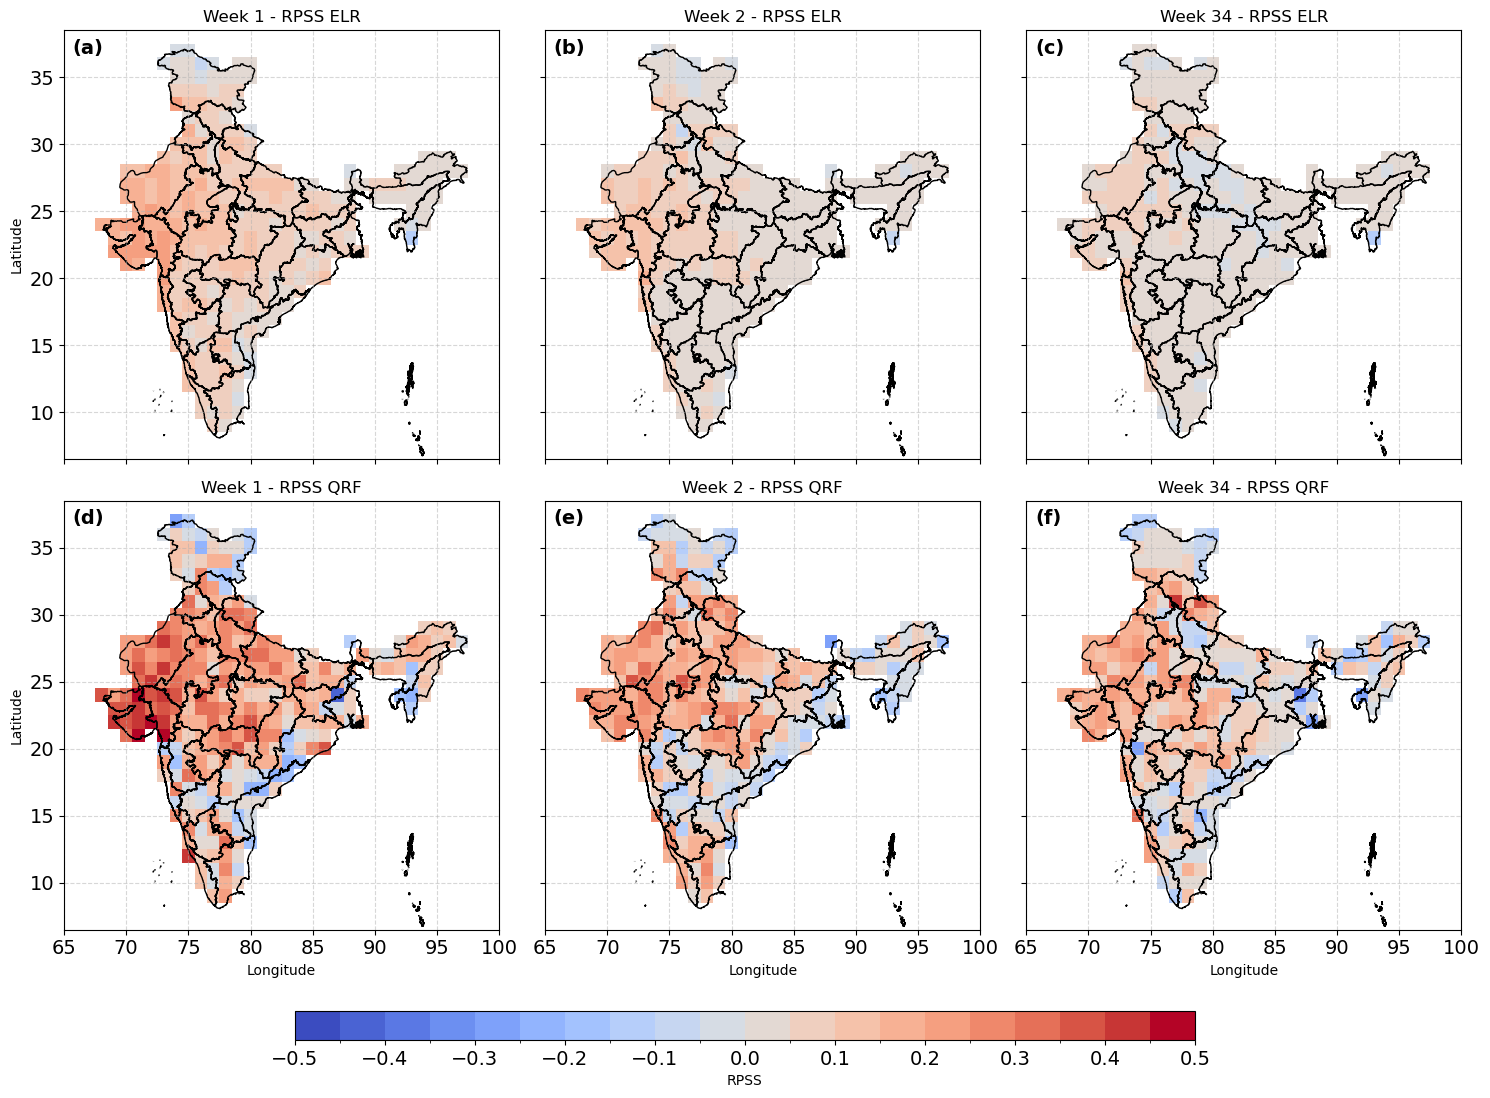

In [67]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import geopandas as gpd



# Define weeks to plot
weekn = [1, 2, 34]

# Create a 3x2 subplot layout
fig, axes = plt.subplots(2, 3, figsize=(15, 11.5), sharex=True, sharey=True)

# Colorbar and level settings
orange_cmap = 'coolwarm'  # Color scheme
rps_vmin, rps_vmax = -0.5, 0.5  # Limits for plots
rps_levels = 21  # Number of levels

# Store contour handles
contours_orange = []

for i, week in enumerate(weekn):  
    # Load datasets
    elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{week}_2022_2024.nc')['prcp']
    qrf_prob = np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{week}_tuned_terciles_2022_2024.npy')
    classes = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_Week{week}_2022_2024.nc")['prcp']
    
    class_values = classes.values
    probs = elr_probs.values

    # Compute RPS scores
    pp = rps_clim(class_values)
    rps_elr = rps_forecast_simple(class_values, probs)
    qrf_prob_rotated = np.transpose(qrf_prob, axes=(2, 3, 0, 1))  # Match (T, category, Y, X)
    rps_qrf = rps_forecast_simple(class_values, qrf_prob_rotated)

    # Coordinate extraction
    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]

    # Convert to xarray for smoothing and plotting
    rps_ELR = np.mean(rps_elr, axis=0)
    rps_QRF = np.mean(rps_qrf, axis=0)

    rps_climo = xr.DataArray(pp, dims=["Y", "X"], coords={"Y": Y, "X": X})
    elr_rps_week = xr.DataArray(rps_ELR, dims=["Y", "X"], coords={"Y": Y, "X": X})
    qrf_rps_week = xr.DataArray(rps_QRF, dims=["Y", "X"], coords={"Y": Y, "X": X})

    # Compute RPSS
    rpss_ELR = 1 - (rps_ELR / pp)
    rpss_QRF = 1 - (rps_QRF / pp)

    # Convert to xarray for plotting
    rpss_ELR_xr = xr.DataArray(rpss_ELR, dims=["Y", "X"], coords={"Y": Y, "X": X})
    rpss_QRF_xr = xr.DataArray(rpss_QRF, dims=["Y", "X"], coords={"Y": Y, "X": X})

    # Plot QRF panel
    contour1 = rpss_ELR_xr.plot(ax=axes[0, i], cmap=orange_cmap, levels=rps_levels, vmin=rps_vmin, vmax=rps_vmax, add_colorbar=False,extend='neither')
    axes[0, i].set_title(f'Week {week} - RPSS ELR')
    gdf_st.plot(ax=axes[0, i], color="none", edgecolor="black", linewidth=1)
    contours_orange.append(contour1)

    # Plot ELR panel
    contour2 = rpss_QRF_xr.plot(ax=axes[1, i], cmap=orange_cmap, levels=rps_levels, vmin=rps_vmin, vmax=rps_vmax, add_colorbar=False,extend='neither')
    axes[1, i].set_title(f'Week {week} - RPSS QRF')
    gdf_st.plot(ax=axes[1, i], color="none", edgecolor="black", linewidth=1)
    contours_orange.append(contour2)

# Set axis labels
for row in range(2):
    for col in range(3):
        if col == 0:
            axes[row, col].set_ylabel("Latitude")
        else:
            axes[row, col].set_ylabel("")
        if row == 1:
            axes[row, col].set_xlabel("Longitude")
        else:
            axes[row, col].set_xlabel("")

min_longitude, max_longitude = X.min().item(), X.max().item()
longitude_ticks = np.arange(np.floor(min_longitude / 5) * 5, np.ceil(max_longitude / 5) * 5 + 1, 5)

for ax in axes[1, :]:  # Apply only to bottom row
    ax.set_xticks(longitude_ticks)

# **Customize tick labels**
i=0
for ax in axes.flatten():
    ax.tick_params(axis='both', labelsize=tick_fontsize)
    ax.grid(True, linestyle="--", alpha=0.5)    
    ax.text(0.02, 0.98, f"({chr(97 + i)})", transform=ax.transAxes, 
            fontsize=14, weight='bold', va='top', ha='left', color='black')
    i=i+1
# Create shared horizontal colorbar
cbar_ax1 = fig.add_axes([0.2, 0.08, 0.6, 0.025])  # [left, bottom, width, height]
cbar1 = fig.colorbar(contours_orange[-1], cax=cbar_ax1, orientation='horizontal')
cbar1.set_label("RPSS")
cbar1.ax.tick_params(labelsize=14)
cbar1.set_ticks([-0.5,-0.4,- 0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3,0.4,0.5])

# Layout adjustments
plt.tight_layout(rect=[0, 0.12, 1, 1])  # Leave space for colorbar
# plt.savefig("rpss_comparison.pdf", dpi=300)
plt.show()


week-1: QRF RPS = 0.3858, ELR RPS = 0.4132, ELR-QRF = +0.0274
week-2: QRF RPS = 0.4081, ELR RPS = 0.4317, ELR-QRF = +0.0235
weeks 3-4: QRF RPS = 0.4208, ELR RPS = 0.4392, ELR-QRF = +0.0184


/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_33968/3003765863.py:503: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


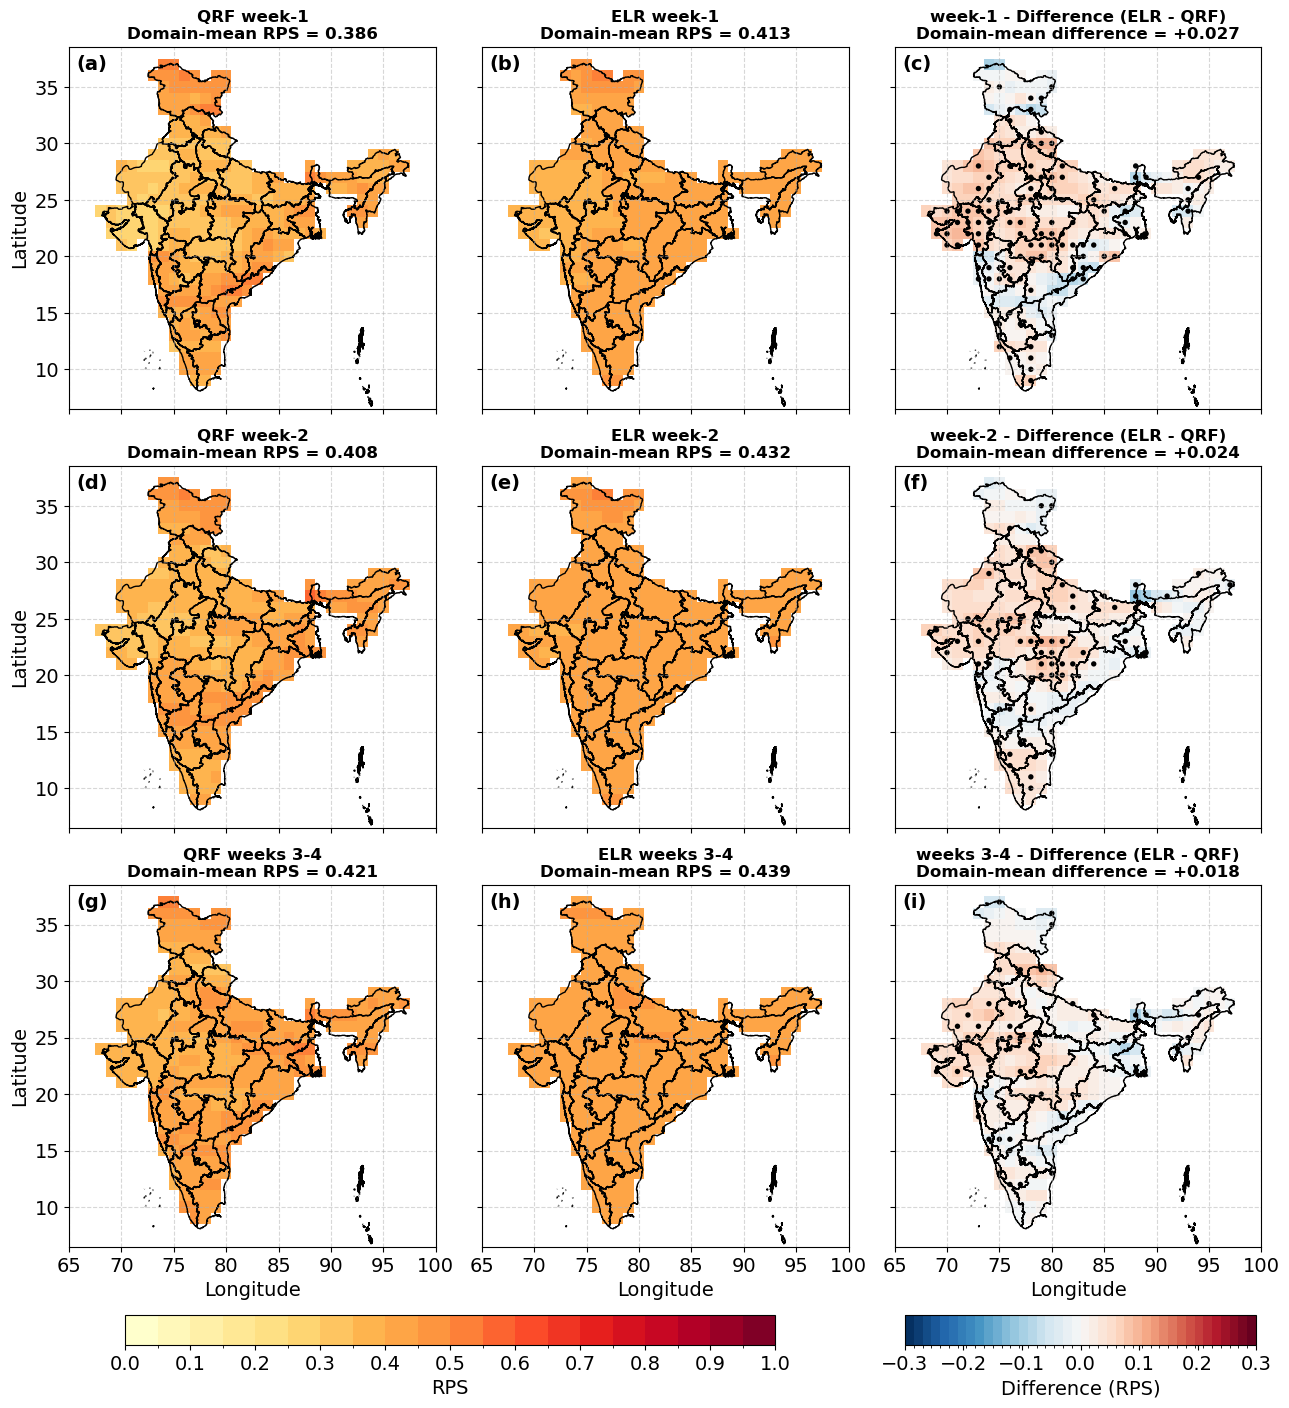

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

weekn = [1, 2, 34]

# Create a 3x3 subplot layout
fig, axes = plt.subplots(
    3, 3,
    figsize=(13, 15),
    sharex=True,
    sharey=True
)

# ---------------------------------------------------------
# Colorbar and contour settings
# ---------------------------------------------------------
orange_cmap = 'YlOrRd'

rps_vmin, rps_vmax = 0, 1.0
rps_levels = 21

diff_vmin, diff_vmax = -0.3, 0.3
diff_levels = 41

# ---------------------------------------------------------
# Font settings
# ---------------------------------------------------------
label_fontsize = 14
tick_fontsize = 14
title_fontsize = 12
colorbar_fontsize = 14

titles = [
    'week-1',
    'week-2',
    'weeks 3-4'
]

# Store contour objects for shared colorbars
contours_orange = []
contours_rdbu = []


# =========================================================
# LOOP THROUGH FORECAST LEAD TIMES
# =========================================================
for i, (week, title) in enumerate(zip(weekn, titles)):

    # -----------------------------------------------------
    # Load data
    # -----------------------------------------------------
    elr_probs = xr.open_dataset(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/ELR_output/ELR_test_prob_Week{week}_2022_2024.nc'
    )['prcp']

    qrf_prob = np.load(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/QRF_output/week_{week}_tuned_terciles_2022_2024.npy'
    )

    classes = xr.open_dataset(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/ELR_output/ELR_test_category_Week{week}_2022_2024.nc'
    )['prcp']


    # -----------------------------------------------------
    # Convert to numpy arrays
    # -----------------------------------------------------
    class_values = classes.values
    probs = elr_probs.values


    # -----------------------------------------------------
    # Calculate RPS
    # -----------------------------------------------------
    rps_elr = rps_forecast_simple(
        class_values,
        probs
    )

    # Rearrange QRF dimensions to match ELR structure
    qrf_prob_rotated = np.transpose(
        qrf_prob,
        axes=(2, 3, 0, 1)
    )

    rps_qrf = rps_forecast_simple(
        class_values,
        qrf_prob_rotated
    )


    # -----------------------------------------------------
    # Coordinates
    # -----------------------------------------------------
    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]


    # -----------------------------------------------------
    # Convert RPS arrays to xarray DataArrays
    # -----------------------------------------------------
    qrf_rps = xr.DataArray(
        rps_qrf,
        dims=["T", "Y", "X"],
        coords={
            "T": T,
            "Y": Y,
            "X": X
        },
        name="rps"
    )

    elr_rps = xr.DataArray(
        rps_elr,
        dims=["T", "Y", "X"],
        coords={
            "T": T,
            "Y": Y,
            "X": X
        },
        name="rps"
    )


    # =====================================================
    # DOMAIN-AVERAGED RPS
    # =====================================================
    # Calculate using ORIGINAL / UNSMOOTHED data.
    # Mean is taken over all test dates and all grid points.
    # -----------------------------------------------------

    domain_mean_qrf = qrf_rps.mean(
        dim=["T", "Y", "X"],
        skipna=True
    ).item()

    domain_mean_elr = elr_rps.mean(
        dim=["T", "Y", "X"],
        skipna=True
    ).item()

    # Difference defined as ELR - QRF
    # Positive value => lower RPS for QRF => QRF performs better
    domain_mean_diff = (
        (elr_rps - qrf_rps)
        .mean(
            dim=["T", "Y", "X"],
            skipna=True
        )
        .item()
    )

    print(
        f"{title}: "
        f"QRF RPS = {domain_mean_qrf:.4f}, "
        f"ELR RPS = {domain_mean_elr:.4f}, "
        f"ELR-QRF = {domain_mean_diff:+.4f}"
    )


    # -----------------------------------------------------
    # Smooth time-dependent RPS fields
    # Used for significance / existing workflow
    # -----------------------------------------------------
    smqrf_rps = smooth_xarray_with_nan(
        qrf_rps,
        sigma=1,
        iterations=1
    )

    smelr_rps = smooth_xarray_with_nan(
        elr_rps,
        sigma=1,
        iterations=1
    )


    # -----------------------------------------------------
    # Statistical significance
    # -----------------------------------------------------
    significant_points, significant_lat_lon = \
        compute_significant_diff_grid(
            qrf_rps,
            elr_rps
        )


    # -----------------------------------------------------
    # Time-mean ELR RPS map
    # -----------------------------------------------------
    rps_ELR = np.mean(
        rps_elr,
        axis=0
    )

    smrps_ELR_week = smooth_xarray_with_nan(
        xr.DataArray(
            rps_ELR,
            dims=["Y", "X"],
            coords={
                "Y": Y,
                "X": X
            },
            name="rps"
        ),
        sigma=1,
        iterations=1
    )


    # -----------------------------------------------------
    # Time-mean QRF RPS map
    # -----------------------------------------------------
    rps_QRF = np.mean(
        rps_qrf,
        axis=0
    )

    smrps_QRF_week = smooth_xarray_with_nan(
        xr.DataArray(
            rps_QRF,
            dims=["Y", "X"],
            coords={
                "Y": Y,
                "X": X
            },
            name="rps"
        ),
        sigma=1,
        iterations=1
    )


    row = i


    # =====================================================
    # PANEL 1: QRF RPS
    # =====================================================
    contour1 = smrps_QRF_week.plot(
        ax=axes[row, 0],
        cmap=orange_cmap,
        levels=rps_levels,
        vmin=rps_vmin,
        vmax=rps_vmax,
        add_colorbar=False
    )

    axes[row, 0].set_title(
        f'QRF {title}\n'
        f'Domain-mean RPS = {domain_mean_qrf:.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    contours_orange.append(contour1)

    gdf_st.plot(
        ax=axes[row, 0],
        color="none",
        edgecolor="black",
        linewidth=1
    )


    # =====================================================
    # PANEL 2: ELR RPS
    # =====================================================
    contour2 = smrps_ELR_week.plot(
        ax=axes[row, 1],
        cmap=orange_cmap,
        levels=rps_levels,
        vmin=rps_vmin,
        vmax=rps_vmax,
        add_colorbar=False
    )

    axes[row, 1].set_title(
        f'ELR {title}\n'
        f'Domain-mean RPS = {domain_mean_elr:.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    contours_orange.append(contour2)

    gdf_st.plot(
        ax=axes[row, 1],
        color="none",
        edgecolor="black",
        linewidth=1
    )


    # =====================================================
    # PANEL 3: ELR - QRF DIFFERENCE
    # =====================================================
    diff = smrps_ELR_week - smrps_QRF_week

    contour3 = diff.plot(
        ax=axes[row, 2],
        cmap='RdBu_r',
        levels=diff_levels,
        vmin=diff_vmin,
        vmax=diff_vmax,
        add_colorbar=False
    )

    axes[row, 2].set_title(
        f'{title} - Difference (ELR - QRF)\n'
        f'Domain-mean difference = {domain_mean_diff:+.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    contours_rdbu.append(contour3)

    gdf_st.plot(
        ax=axes[row, 2],
        color="none",
        edgecolor="black",
        linewidth=1
    )


    # -----------------------------------------------------
    # Overlay statistically significant points
    # -----------------------------------------------------
    for j in range(len(significant_points)):

        y_value = significant_lat_lon[j][0]
        x_value = significant_lat_lon[j][1]

        axes[row, 2].scatter(
            x_value,
            y_value,
            color='black',
            marker='o',
            s=15,
            edgecolor='none',
            linewidth=0.8
        )


# =========================================================
# AXIS LABELS
# =========================================================
for row in range(3):
    for col in range(3):

        if col == 0:
            axes[row, col].set_ylabel(
                "Latitude",
                fontsize=label_fontsize
            )
        else:
            axes[row, col].set_ylabel("")


for col in range(3):
    for row in range(3):

        if row == 2:
            axes[row, col].set_xlabel(
                "Longitude",
                fontsize=label_fontsize
            )
        else:
            axes[row, col].set_xlabel("")


# =========================================================
# LONGITUDE TICKS
# =========================================================
min_longitude = X.min().item()
max_longitude = X.max().item()

longitude_ticks = np.arange(
    np.floor(min_longitude / 5) * 5,
    np.ceil(max_longitude / 5) * 5 + 1,
    5
)

for ax in axes[2, :]:
    ax.set_xticks(longitude_ticks)


# =========================================================
# TICK LABELS, GRID, PANEL LABELS
# =========================================================
i = 0

for ax in axes.flatten():

    ax.tick_params(
        axis='both',
        labelsize=tick_fontsize
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    ax.text(
        0.02,
        0.98,
        f"({chr(97 + i)})",
        transform=ax.transAxes,
        fontsize=14,
        weight='bold',
        va='top',
        ha='left',
        color='black'
    )

    i += 1


# =========================================================
# COLORBAR FOR QRF AND ELR RPS
# =========================================================
cbar_ax1 = fig.add_axes(
    [0.1, 0.1, 0.5, 0.02]
)

cbar1 = fig.colorbar(
    contours_orange[0],
    cax=cbar_ax1,
    orientation='horizontal'
)

cbar1.set_label(
    "RPS",
    fontsize=colorbar_fontsize
)

cbar1.ax.tick_params(
    labelsize=tick_fontsize
)

cbar1.set_ticks(
    [
        0,
        0.1,
        0.2,
        0.3,
        0.4,
        0.5,
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ]
)


# =========================================================
# COLORBAR FOR DIFFERENCE
# =========================================================
cbar_ax2 = fig.add_axes(
    [0.7, 0.1, 0.27, 0.02]
)

cbar2 = fig.colorbar(
    contours_rdbu[0],
    cax=cbar_ax2,
    orientation='horizontal'
)

cbar2.set_label(
    "Difference (RPS)",
    fontsize=colorbar_fontsize
)

cbar2.ax.tick_params(
    labelsize=tick_fontsize
)

cbar2.set_ticks(
    [
        -0.3,
        -0.2,
        -0.1,
        0,
        0.1,
        0.2,
        0.3
    ]
)


# =========================================================
# LAYOUT
# =========================================================
plt.tight_layout(
    rect=[0, 0.12, 1, 1]
)


# =========================================================
# SAVE FIGURE
# =========================================================
plt.savefig(
    "/Users/bohar/Documents/abstract_papers/QRF/figures/rps_plot_nov26.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


--------------------------------------
week-1
--------------------------------------
QRF domain-mean RPS = 0.3858
ELR domain-mean RPS = 0.4132
ELR - QRF difference = +0.0274
QRF RPS < ELR RPS: 233/315 grid points (74.0%)
ELR RPS < QRF RPS: 82/315 grid points (26.0%)
Equal = 0 grid points

--------------------------------------
week-2
--------------------------------------
QRF domain-mean RPS = 0.4081
ELR domain-mean RPS = 0.4317
ELR - QRF difference = +0.0235
QRF RPS < ELR RPS: 224/315 grid points (71.1%)
ELR RPS < QRF RPS: 91/315 grid points (28.9%)
Equal = 0 grid points

--------------------------------------
weeks 3-4
--------------------------------------
QRF domain-mean RPS = 0.4208
ELR domain-mean RPS = 0.4392
ELR - QRF difference = +0.0184
QRF RPS < ELR RPS: 224/315 grid points (71.1%)
ELR RPS < QRF RPS: 91/315 grid points (28.9%)
Equal = 0 grid points


/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_33968/2360195400.py:607: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


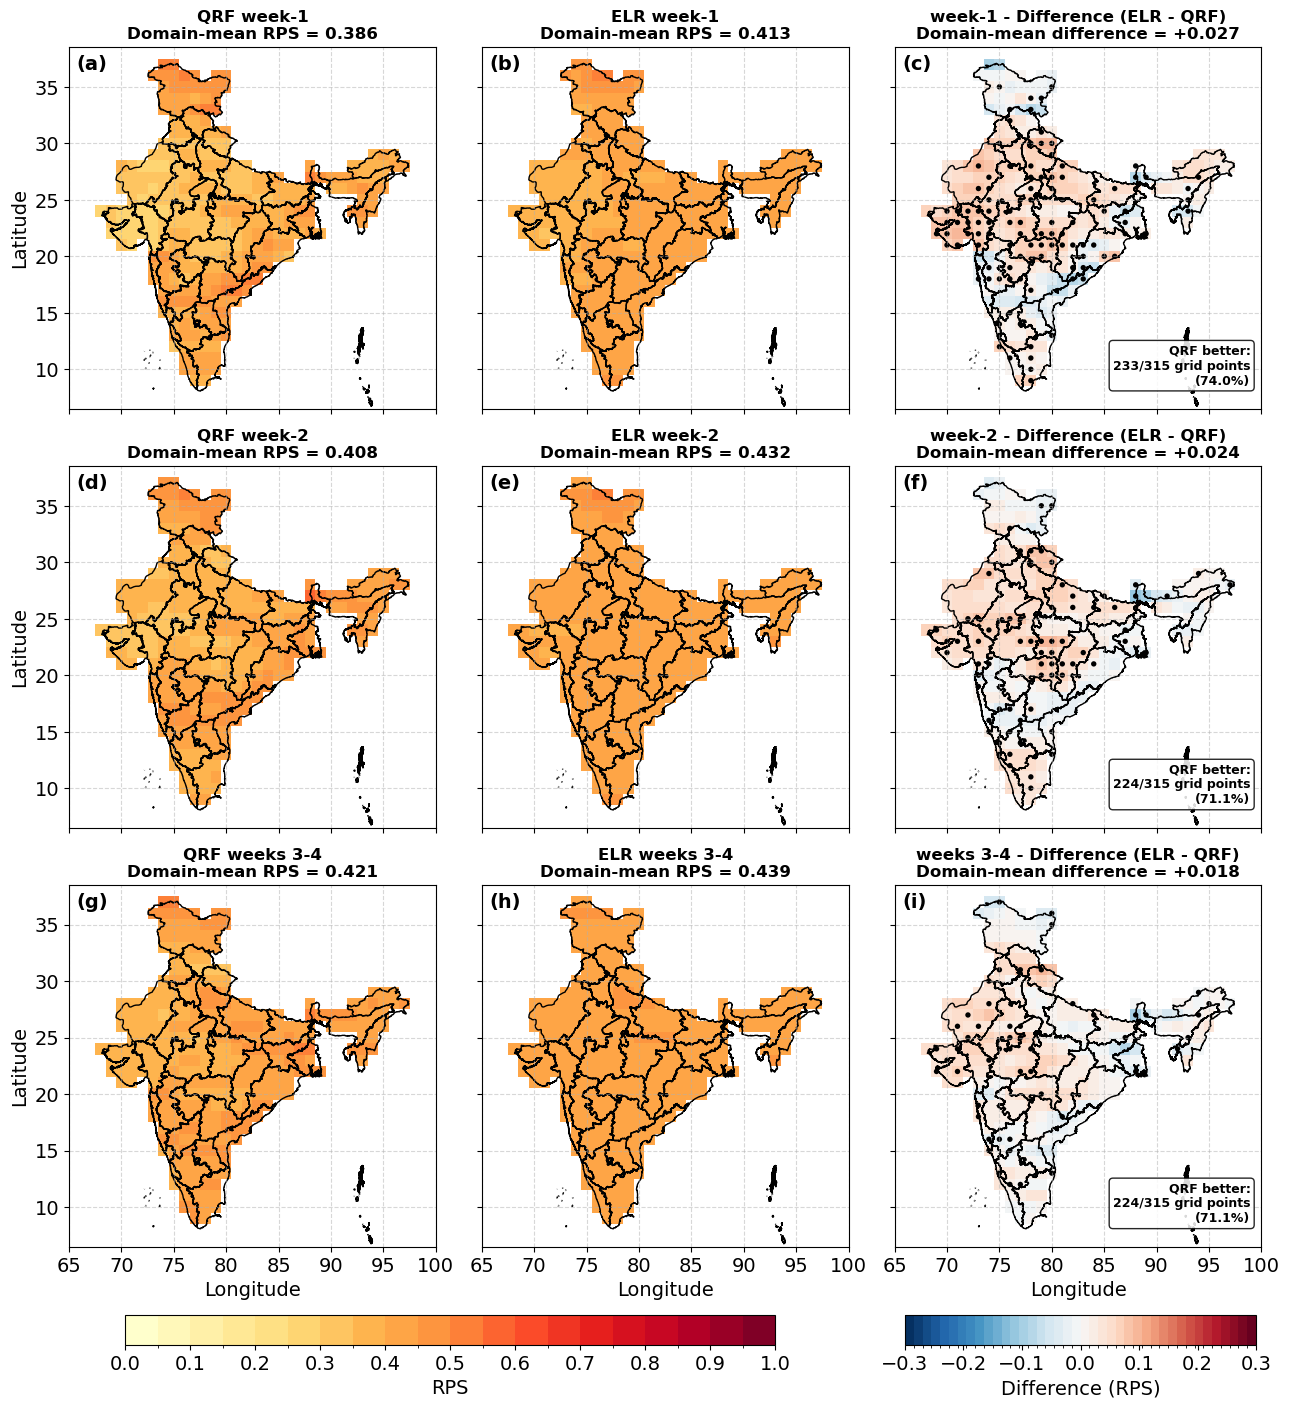

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

weekn = [1, 2, 34]

# =========================================================
# CREATE FIGURE
# =========================================================
fig, axes = plt.subplots(
    3, 3,
    figsize=(13, 15),
    sharex=True,
    sharey=True
)

# =========================================================
# COLORBAR AND CONTOUR SETTINGS
# =========================================================
orange_cmap = 'YlOrRd'

rps_vmin, rps_vmax = 0, 1.0
rps_levels = 21

diff_vmin, diff_vmax = -0.3, 0.3
diff_levels = 41

# =========================================================
# FONT SETTINGS
# =========================================================
label_fontsize = 14
tick_fontsize = 14
title_fontsize = 12
colorbar_fontsize = 14

titles = [
    'week-1',
    'week-2',
    'weeks 3-4'
]

# Store contour objects
contours_orange = []
contours_rdbu = []

# Optional: store results
domain_rps_results = {}

# =========================================================
# LOOP THROUGH FORECAST LEAD TIMES
# =========================================================
for i, (week, title) in enumerate(zip(weekn, titles)):

    # -----------------------------------------------------
    # Load data
    # -----------------------------------------------------
    elr_probs = xr.open_dataset(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/ELR_output/'
        f'ELR_test_prob_Week{week}_2022_2024.nc'
    )['prcp']

    qrf_prob = np.load(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/QRF_output/'
        f'week_{week}_tuned_terciles_2022_2024.npy'
    )

    classes = xr.open_dataset(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/ELR_output/'
        f'ELR_test_category_Week{week}_2022_2024.nc'
    )['prcp']

    # -----------------------------------------------------
    # Convert to numpy arrays
    # -----------------------------------------------------
    class_values = classes.values
    probs = elr_probs.values

    # =====================================================
    # CALCULATE RPS
    # =====================================================
    rps_elr = rps_forecast_simple(
        class_values,
        probs
    )

    # Rearrange QRF probabilities to:
    # T, category, Y, X
    qrf_prob_rotated = np.transpose(
        qrf_prob,
        axes=(2, 3, 0, 1)
    )

    rps_qrf = rps_forecast_simple(
        class_values,
        qrf_prob_rotated
    )

    # -----------------------------------------------------
    # Coordinates
    # -----------------------------------------------------
    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]

    # =====================================================
    # CONVERT RPS TO XARRAY
    # =====================================================
    qrf_rps = xr.DataArray(
        rps_qrf,
        dims=["T", "Y", "X"],
        coords={
            "T": T,
            "Y": Y,
            "X": X
        },
        name="rps"
    )

    elr_rps = xr.DataArray(
        rps_elr,
        dims=["T", "Y", "X"],
        coords={
            "T": T,
            "Y": Y,
            "X": X
        },
        name="rps"
    )

    # =====================================================
    # DOMAIN-MEAN RPS
    # =====================================================
    # Use ORIGINAL / UNSMOOTHED values
    # =====================================================
    domain_mean_qrf = qrf_rps.mean(
        dim=["T", "Y", "X"],
        skipna=True
    ).item()

    domain_mean_elr = elr_rps.mean(
        dim=["T", "Y", "X"],
        skipna=True
    ).item()

    # Positive difference means QRF has lower RPS
    domain_mean_diff = (
        (elr_rps - qrf_rps)
        .mean(
            dim=["T", "Y", "X"],
            skipna=True
        )
        .item()
    )

    # =====================================================
    # GRID-POINT MEAN RPS
    # =====================================================
    # First average through time at each grid point.
    # Then compare QRF and ELR spatially.
    # =====================================================
    grid_mean_qrf = qrf_rps.mean(
        dim="T",
        skipna=True
    )

    grid_mean_elr = elr_rps.mean(
        dim="T",
        skipna=True
    )

    qrf_values = grid_mean_qrf.values
    elr_values = grid_mean_elr.values

    # Grid points where both methods have valid values
    valid_mask = (
        np.isfinite(qrf_values)
        & np.isfinite(elr_values)
    )

    total_valid_points = int(
        np.sum(valid_mask)
    )

    # -----------------------------------------------------
    # RPS: LOWER IS BETTER
    # -----------------------------------------------------
    qrf_better_points = int(
        np.sum(
            (qrf_values < elr_values)
            & valid_mask
        )
    )

    elr_better_points = int(
        np.sum(
            (elr_values < qrf_values)
            & valid_mask
        )
    )

    equal_points = int(
        np.sum(
            np.isclose(
                qrf_values,
                elr_values,
                atol=1e-12
            )
            & valid_mask
        )
    )

    percent_qrf_better = (
        100.0 * qrf_better_points / total_valid_points
        if total_valid_points > 0
        else np.nan
    )

    percent_elr_better = (
        100.0 * elr_better_points / total_valid_points
        if total_valid_points > 0
        else np.nan
    )

    # -----------------------------------------------------
    # Store results
    # -----------------------------------------------------
    domain_rps_results[week] = {
        "QRF_mean": domain_mean_qrf,
        "ELR_mean": domain_mean_elr,
        "ELR_minus_QRF": domain_mean_diff,
        "QRF_better_points": qrf_better_points,
        "ELR_better_points": elr_better_points,
        "valid_grid_points": total_valid_points,
        "QRF_better_percent": percent_qrf_better,
        "ELR_better_percent": percent_elr_better
    }

    # =====================================================
    # PRINT RESULTS
    # =====================================================
    print("\n--------------------------------------")
    print(title)
    print("--------------------------------------")

    print(
        f"QRF domain-mean RPS = "
        f"{domain_mean_qrf:.4f}"
    )

    print(
        f"ELR domain-mean RPS = "
        f"{domain_mean_elr:.4f}"
    )

    print(
        f"ELR - QRF difference = "
        f"{domain_mean_diff:+.4f}"
    )

    print(
        f"QRF RPS < ELR RPS: "
        f"{qrf_better_points}/{total_valid_points} "
        f"grid points ({percent_qrf_better:.1f}%)"
    )

    print(
        f"ELR RPS < QRF RPS: "
        f"{elr_better_points}/{total_valid_points} "
        f"grid points ({percent_elr_better:.1f}%)"
    )

    print(
        f"Equal = {equal_points} grid points"
    )

    # =====================================================
    # STATISTICAL SIGNIFICANCE
    # =====================================================
    significant_points, significant_lat_lon = \
        compute_significant_diff_grid(
            qrf_rps,
            elr_rps
        )

    # =====================================================
    # TIME-MEAN RPS MAPS
    # =====================================================
    # Use unsmoothed time means
    # =====================================================
    rps_ELR = elr_rps.mean(
        dim="T",
        skipna=True
    )

    rps_QRF = qrf_rps.mean(
        dim="T",
        skipna=True
    )

    # -----------------------------------------------------
    # Smooth only for plotting
    # -----------------------------------------------------
    smrps_ELR_week = smooth_xarray_with_nan(
        rps_ELR,
        sigma=1,
        iterations=1
    )

    smrps_QRF_week = smooth_xarray_with_nan(
        rps_QRF,
        sigma=1,
        iterations=1
    )

    row = i

    # =====================================================
    # PANEL 1: QRF RPS
    # =====================================================
    contour1 = smrps_QRF_week.plot(
        ax=axes[row, 0],
        cmap=orange_cmap,
        levels=rps_levels,
        vmin=rps_vmin,
        vmax=rps_vmax,
        add_colorbar=False
    )

    axes[row, 0].set_title(
        f'QRF {title}\n'
        f'Domain-mean RPS = {domain_mean_qrf:.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    contours_orange.append(contour1)

    gdf_st.plot(
        ax=axes[row, 0],
        color="none",
        edgecolor="black",
        linewidth=1
    )

    # =====================================================
    # PANEL 2: ELR RPS
    # =====================================================
    contour2 = smrps_ELR_week.plot(
        ax=axes[row, 1],
        cmap=orange_cmap,
        levels=rps_levels,
        vmin=rps_vmin,
        vmax=rps_vmax,
        add_colorbar=False
    )

    axes[row, 1].set_title(
        f'ELR {title}\n'
        f'Domain-mean RPS = {domain_mean_elr:.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    contours_orange.append(contour2)

    gdf_st.plot(
        ax=axes[row, 1],
        color="none",
        edgecolor="black",
        linewidth=1
    )

    # =====================================================
    # PANEL 3: DIFFERENCE (ELR - QRF)
    # =====================================================
    diff = (
        smrps_ELR_week
        - smrps_QRF_week
    )

    contour3 = diff.plot(
        ax=axes[row, 2],
        cmap='RdBu_r',
        levels=diff_levels,
        vmin=diff_vmin,
        vmax=diff_vmax,
        add_colorbar=False
    )

    axes[row, 2].set_title(
        f'{title} - Difference (ELR - QRF)\n'
        f'Domain-mean difference = {domain_mean_diff:+.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    contours_rdbu.append(contour3)

    gdf_st.plot(
        ax=axes[row, 2],
        color="none",
        edgecolor="black",
        linewidth=1
    )

    # =====================================================
    # ADD GRID-POINT PERCENTAGE TO DIFFERENCE PANEL
    # =====================================================
    axes[row, 2].text(
        0.97,
        0.06,
        f'QRF better:\n'
        f'{qrf_better_points}/{total_valid_points} grid points\n'
        f'({percent_qrf_better:.1f}%)',
        transform=axes[row, 2].transAxes,
        fontsize=9,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            alpha=0.85,
            boxstyle='round,pad=0.3'
        )
    )

    # =====================================================
    # OVERLAY STATISTICALLY SIGNIFICANT POINTS
    # =====================================================
    for j in range(len(significant_points)):

        y_value = significant_lat_lon[j][0]
        x_value = significant_lat_lon[j][1]

        axes[row, 2].scatter(
            x_value,
            y_value,
            color='black',
            marker='o',
            s=15,
            edgecolor='none',
            linewidth=0.8
        )

# =========================================================
# AXIS LABELS
# =========================================================
for row in range(3):

    for col in range(3):

        if col == 0:

            axes[row, col].set_ylabel(
                "Latitude",
                fontsize=label_fontsize
            )

        else:

            axes[row, col].set_ylabel("")

for col in range(3):

    for row in range(3):

        if row == 2:

            axes[row, col].set_xlabel(
                "Longitude",
                fontsize=label_fontsize
            )

        else:

            axes[row, col].set_xlabel("")

# =========================================================
# LONGITUDE TICKS
# =========================================================
min_longitude = X.min().item()
max_longitude = X.max().item()

longitude_ticks = np.arange(
    np.floor(min_longitude / 5) * 5,
    np.ceil(max_longitude / 5) * 5 + 1,
    5
)

for ax in axes[2, :]:

    ax.set_xticks(
        longitude_ticks
    )

# =========================================================
# PANEL LABELS, TICKS, GRID
# =========================================================
panel_number = 0

for ax in axes.flatten():

    ax.tick_params(
        axis='both',
        labelsize=tick_fontsize
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    ax.text(
        0.02,
        0.98,
        f"({chr(97 + panel_number)})",
        transform=ax.transAxes,
        fontsize=14,
        weight='bold',
        va='top',
        ha='left',
        color='black'
    )

    panel_number += 1

# =========================================================
# COLORBAR: RPS
# =========================================================
cbar_ax1 = fig.add_axes(
    [0.1, 0.1, 0.5, 0.02]
)

cbar1 = fig.colorbar(
    contours_orange[0],
    cax=cbar_ax1,
    orientation='horizontal'
)

cbar1.set_label(
    "RPS",
    fontsize=colorbar_fontsize
)

cbar1.ax.tick_params(
    labelsize=tick_fontsize
)

cbar1.set_ticks(
    [
        0,
        0.1,
        0.2,
        0.3,
        0.4,
        0.5,
        0.6,
        0.7,
        0.8,
        0.9,
        1.0
    ]
)

# =========================================================
# COLORBAR: DIFFERENCE
# =========================================================
cbar_ax2 = fig.add_axes(
    [0.7, 0.1, 0.27, 0.02]
)

cbar2 = fig.colorbar(
    contours_rdbu[0],
    cax=cbar_ax2,
    orientation='horizontal'
)

cbar2.set_label(
    "Difference (RPS)",
    fontsize=colorbar_fontsize
)

cbar2.ax.tick_params(
    labelsize=tick_fontsize
)

cbar2.set_ticks(
    [
        -0.3,
        -0.2,
        -0.1,
        0,
        0.1,
        0.2,
        0.3
    ]
)

# =========================================================
# LAYOUT
# =========================================================
plt.tight_layout(
    rect=[0, 0.12, 1, 1]
)

# =========================================================
# SAVE FIGURE
# =========================================================
plt.savefig(
    "/Users/bohar/Documents/abstract_papers/QRF/"
    "figures/rps_plot_nov26.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()